In [3]:
file = "20181024_d1_0830_0900.csv"


In [4]:
with open(file, "r") as f:
    for i in range(3):
        line = f.readline().strip()
        fields = line.split(";")

        print(f"--- Line {i+1} ---")
        print(f"Total fields: {len(fields)}")
        print(f"Metadata: {fields[:4]}")  # [track_id, type, traveled_d, avg_speed]
        print(f"First vector: {fields[4:16]}")  # [lat, lon, speed, tan_acc, lat_acc, time]
        print()

--- Line 1 ---
Total fields: 10
Metadata: ['track_id', ' type', ' traveled_d', ' avg_speed']
First vector: [' lat', ' lon', ' speed', ' lon_acc', ' lat_acc', ' time']

--- Line 2 ---
Total fields: 2711
Metadata: ['1', ' Car', ' 48.85', ' 9.770344']
First vector: [' 37.977391', ' 23.737688', ' 4.9178', ' 0.0518', ' -0.0299', ' 0.000000', ' 37.977391', ' 23.737688', ' 4.9207', ' -0.0124', ' -0.0354', ' 0.040000']

--- Line 3 ---
Total fields: 2681
Metadata: ['2', ' Motorcycle', ' 98.09', ' 19.839417']
First vector: [' 37.977642', ' 23.737400', ' 16.9759', ' -0.0361', ' -0.0228', ' 0.000000', ' 37.977642', ' 23.737402', ' 16.9739', ' 0.0087', ' -0.0262', ' 0.040000']



In [5]:
import pandas as pd

# List to accumulate the flattened data
flattened_data = []

with open(file, 'r') as f:
    # Skip the first line (header)
    next(f)

    for line in f:
        fields = [x.strip() for x in line.split(';') if x.strip()]

        if len(fields) < 4:
            continue

        # The first 4 fields are fixed for the vehicle
        track_id = fields[0]
        v_type = fields[1]
        traveled_d = fields[2]
        avg_speed = fields[3]

        # From index 4 onwards, data repeats in blocks of 6 variables per frame:
        # [lat, lon, speed, lon_acc, lat_acc, time]
        trajectory = fields[4:]

        for i in range(0, len(trajectory), 6):
            if i + 5 < len(trajectory):
                flattened_data.append({
                    'track_id': track_id,
                    'type': v_type,
                    'lat': float(trajectory[i]),
                    'lon': float(trajectory[i+1]),
                    'speed': float(trajectory[i+2]),
                    'lon_acc': float(trajectory[i+3]),
                    'lat_acc': float(trajectory[i+4]),
                    'time': float(trajectory[i+5])
                })

# Convert the list of dictionaries into a standard DataFrame
df = pd.DataFrame(flattened_data)

# Verify the new structure
print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1446887 entries, 0 to 1446886
Data columns (total 8 columns):
 #   Column    Non-Null Count    Dtype  
---  ------    --------------    -----  
 0   track_id  1446887 non-null  str    
 1   type      1446887 non-null  str    
 2   lat       1446887 non-null  float64
 3   lon       1446887 non-null  float64
 4   speed     1446887 non-null  float64
 5   lon_acc   1446887 non-null  float64
 6   lat_acc   1446887 non-null  float64
 7   time      1446887 non-null  float64
dtypes: float64(6), str(2)
memory usage: 88.3 MB
None
  track_id type        lat        lon   speed  lon_acc  lat_acc  time
0        1  Car  37.977391  23.737688  4.9178   0.0518  -0.0299  0.00
1        1  Car  37.977391  23.737688  4.9207  -0.0124  -0.0354  0.04
2        1  Car  37.977391  23.737688  4.9160  -0.0519  -0.0413  0.08
3        1  Car  37.977390  23.737688  4.9057  -0.0914  -0.0478  0.12
4        1  Car  37.977390  23.737689  4.8871  -0.1679  -0.0550  0.16


In [6]:
dt = 0.04
window_size = 25
accel_threshold = 9.0


In [7]:
from scipy.signal import savgol_filter

def process_kinematics(group):
    # Skip smoothing for short trajectories to avoid Savitzky-Golay window size errors
    if len(group) < window_size:
        group['speed_smooth'] = group['speed']
        group['accel_raw'] = 0
        group['accel_smooth'] = 0
        return group

    # Smooth speed to mitigate high-frequency noise before differentiation
    group['speed_smooth'] = savgol_filter(group['speed'], window_length=window_size, polyorder=1)

    group['accel_raw'] = group['speed'].diff() / dt
    group['accel_smooth'] = group['speed_smooth'].diff() / dt

    return group

In [8]:
df = df.sort_values(by=['track_id', 'time'])

df = df.groupby('track_id').apply(process_kinematics, include_groups=False).reset_index(level=0).dropna()

df_outliers = df[(df['accel_smooth'] > accel_threshold) | (df['accel_smooth'] < -accel_threshold)]
df_clean = df[(df['accel_smooth'] <= accel_threshold) & (df['accel_smooth'] >= -accel_threshold)]

print(f"Anomalies removed: {len(df_outliers)} ({(len(df_outliers)/len(df))*100:.2f}%)")

Anomalies removed: 13194 (0.91%)


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

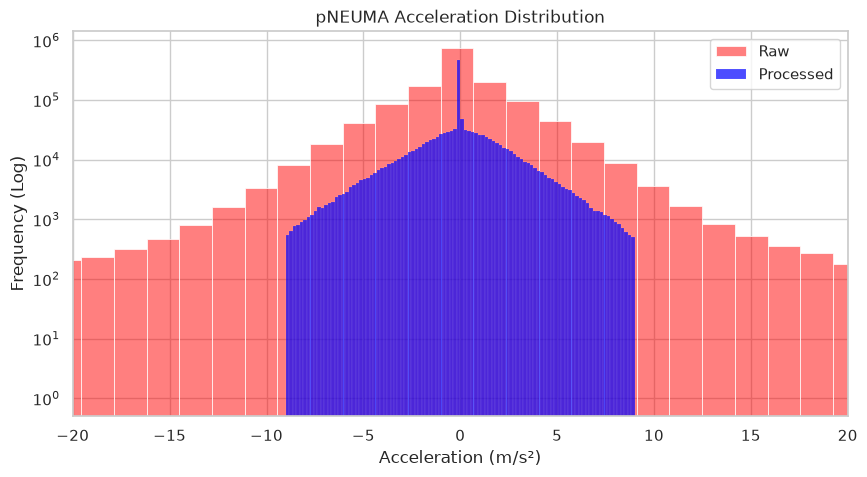

In [10]:
# pNEUMA Acceleration Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['accel_raw'], bins=100, color='red', alpha=0.5, label='Raw')
sns.histplot(df_clean['accel_smooth'], bins=100, color='blue', alpha=0.7, label='Processed')
plt.yscale('log')
plt.xlim(-20, 20)
plt.xlabel('Acceleration (m/s²)')
plt.ylabel('Frequency (Log)')
plt.title('pNEUMA Acceleration Distribution')
plt.legend()
plt.show()

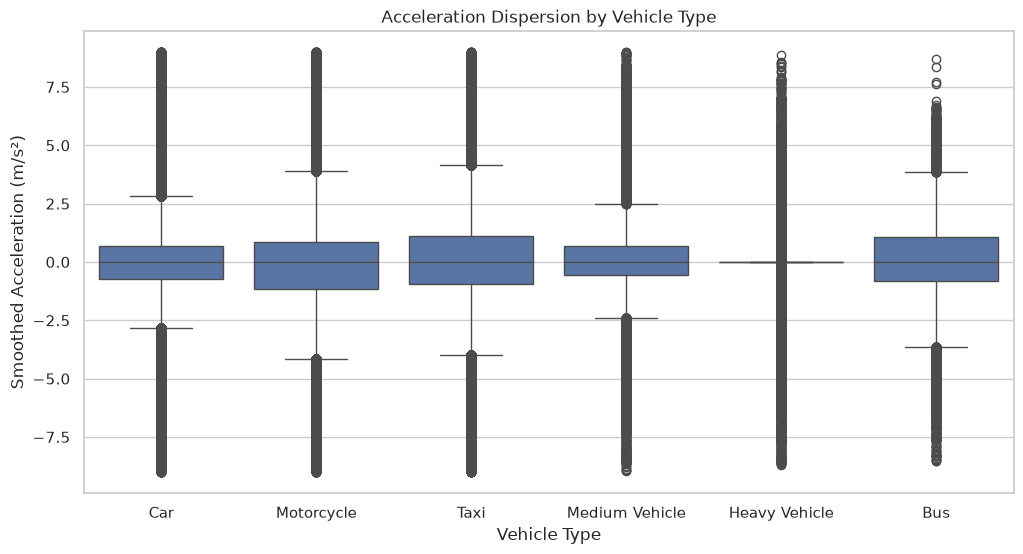

In [11]:
# Acceleration Dispersion by Vehicle Type
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x='type', y='accel_smooth', showfliers=True)
plt.xlabel('Vehicle Type')
plt.ylabel('Smoothed Acceleration (m/s²)')
plt.title('Acceleration Dispersion by Vehicle Type')
plt.show()

In [12]:
accel_df = df_clean[df_clean['accel_smooth'] > 0.1]
decel_df = df_clean[df_clean['accel_smooth'] < -0.1]

sumo_params = pd.DataFrame({
    'Accel_Mean': accel_df.groupby('type')['accel_smooth'].mean(),
    'Accel_Std': accel_df.groupby('type')['accel_smooth'].std(),
    'Decel_Mean': decel_df.groupby('type')['accel_smooth'].mean().abs(),
    'Decel_Std': decel_df.groupby('type')['accel_smooth'].std(),
    'Speed_Mean': df_clean.groupby('type')['speed_smooth'].mean(),
})

print(sumo_params.round(2))

                Accel_Mean  Accel_Std  Decel_Mean  Speed_Mean
type                                                         
Bus                   1.67       1.21        1.75       18.83
Car                   2.10       1.73        2.14       15.82
Heavy Vehicle         1.72       1.34        1.77        6.17
Medium Vehicle        2.05       1.62        1.92       13.96
Motorcycle            2.41       1.98        2.47       19.58
Taxi                  2.12       1.70        2.18       18.00


In [13]:
# Export sumo_params to CSV
sumo_params.to_csv('sumo_params.csv', index=True)